# Customer Segmentation using K-Means Clustering
This notebook cleans customer data, explores purchasing behavior, finds an optimal K using the Elbow Method and Silhouette Score, applies K-Means, and summarizes customer segments.

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv('customer_data.csv')
df.head()

,CustomerID,Age,Gender,AnnualIncome_k,PurchaseFrequency,AvgOrderValue,SpendingScore,TotalSpend,BusinessSegment
0,10001,40,Female,41.7,5,78.98,7.3,374.62,Low Engagement
1,10002,33,Female,48.1,7,21.50,5.4,138.22,Potential
2,10003,42,Male,77.4,5,57.03,8.9,295.06,Potential
3,10004,52,Female,31.2,11,70.42,8.7,914.48,Low Engagement
4,10005,32,Female,53.1,11,47.41,10.0,411.56,High Value


In [19]:
df.info()
df.isna().sum()
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         500 non-null    int64  
 1   Age                500 non-null    int64  
 2   Gender             500 non-null    object 
 3   AnnualIncome_k     500 non-null    float64
 4   PurchaseFrequency  500 non-null    int64  
 5   AvgOrderValue      500 non-null    float64
 6   SpendingScore      500 non-null    float64
 7   TotalSpend         500 non-null    float64
 8   BusinessSegment    500 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 35.3+ KB


,CustomerID,Age,Gender,AnnualIncome_k,PurchaseFrequency,AvgOrderValue,SpendingScore,TotalSpend,BusinessSegment
count,500.000000,500.000000,500,500.000000,500.000000,500.000000,500.000000,500.000000,500
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,4
top,NaN,NaN,Male,NaN,NaN,NaN,NaN,NaN,Frequent / Budget
freq,NaN,NaN,255,NaN,NaN,NaN,NaN,NaN,131
mean,10250.500000,35.264000,NaN,51.202000,8.858000,54.265720,8.867600,479.755160,NaN
std,144.481833,10.356293,NaN,23.529703,2.699706,17.636279,1.453056,235.996883,NaN
min,10001.000000,18.000000,NaN,15.000000,2.000000,15.000000,2.800000,56.300000,NaN
25%,10125.750000,27.000000,NaN,34.275000,7.000000,42.510000,8.100000,304.462500,NaN
50%,10250.500000,35.000000,NaN,46.450000,9.000000,54.760000,9.500000,450.540000,NaN
75%,10375.250000,42.000000,NaN,61.625000,11.000000,66.425000,10.000000,614.617500,NaN


In [20]:
features = ['AnnualIncome_k','SpendingScore','PurchaseFrequency','AvgOrderValue']
scaler = StandardScaler()
X = scaler.fit_transform(df[features])

C:\Users\Suhas\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Suhas\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Suhas\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Suhas\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

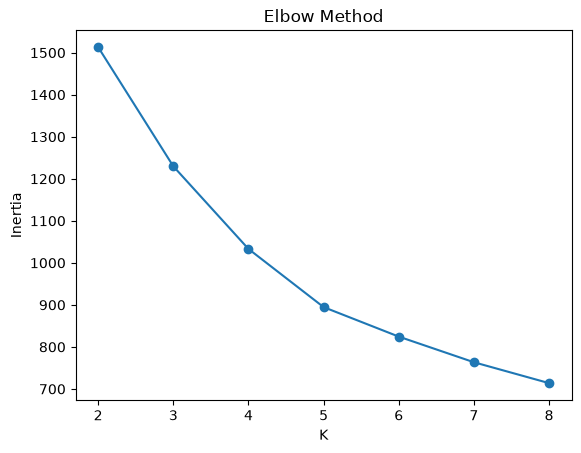

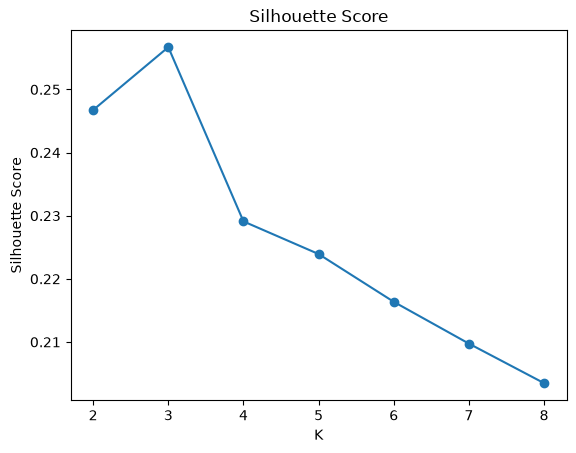

In [21]:
inertias, silhouettes = [], []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, labels))

plt.plot(range(2, 9), inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

plt.plot(range(2, 9), silhouettes, marker='o')
plt.xlabel('K')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.show()

In [22]:
best_k = 3
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)
df.groupby('Cluster')[features].mean().round(2)

C:\Users\Suhas\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,AnnualIncome_k,SpendingScore,PurchaseFrequency,AvgOrderValue
Cluster,,,,
0,40.98,9.64,10.11,57.04
1,43.66,6.98,6.66,46.96
2,86.43,9.19,8.32,56.02


In [24]:
profiles = df.groupby('Cluster')[features].mean()
score = ((profiles['AnnualIncome_k']-profiles['AnnualIncome_k'].mean())/profiles['AnnualIncome_k'].std() +
         (profiles['SpendingScore']-profiles['SpendingScore'].mean())/profiles['SpendingScore'].std())
ordered = score.sort_values().index.tolist()
names = ['Low Value','Developing','Potential High Value','Premium']
name_map = {cl: names[i] if i < len(names) else f'Segment {i+1}' for i, cl in enumerate(ordered)}
df['Segment'] = df['Cluster'].map(name_map)
df.to_csv('customer_segments.csv', index=False)
df.head()

,CustomerID,Age,Gender,AnnualIncome_k,PurchaseFrequency,AvgOrderValue,SpendingScore,TotalSpend,BusinessSegment,Cluster,Segment
0,10001,40,Female,41.7,5,78.98,7.3,374.62,Low Engagement,1,Low Value
1,10002,33,Female,48.1,7,21.50,5.4,138.22,Potential,1,Low Value
2,10003,42,Male,77.4,5,57.03,8.9,295.06,Potential,2,Potential High Value
3,10004,52,Female,31.2,11,70.42,8.7,914.48,Low Engagement,0,Developing
4,10005,32,Female,53.1,11,47.41,10.0,411.56,High Value,0,Developing


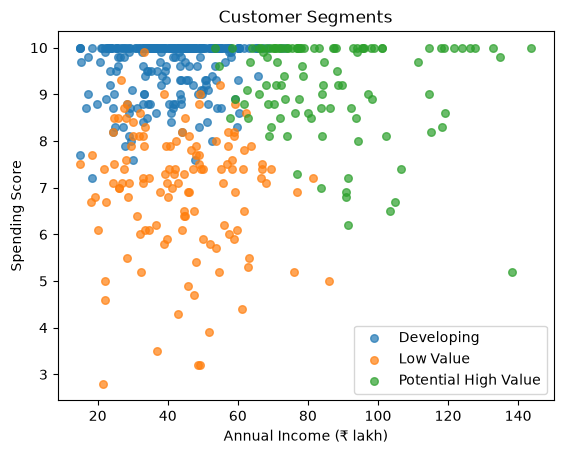

In [25]:
for seg, g in df.groupby('Segment'):
    plt.scatter(g['AnnualIncome_k'], g['SpendingScore'], s=30, alpha=.7, label=seg)
plt.xlabel('Annual Income (₹ lakh)')
plt.ylabel('Spending Score')
plt.title('Customer Segments')
plt.legend()
plt.show()

## Business Insights
- Premium customers can be targeted with loyalty programs and exclusive offers.
- Potential High Value customers can receive cross-sell and upsell campaigns.
- Developing customers may respond to personalized discounts and product recommendations.
- Low Value customers can be addressed with low-cost retention campaigns.